Praktikum 4 - Annoy vs FAISS Flat vs HNSW pada 1 juta vektor 5D, k=10.

Annoy tidak bisa di-build di mesin ini -> dipakai padanan faiss.IndexIVFFlat
(nlist=100, nprobe=10). HNSW memakai faiss.IndexHNSWFlat (pengganti hnswlib),
M=16, efConstruction=200, efSearch=50.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("p4_bandingkan_tiga.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js06-ann-approximate-nearest-neighbors\praktikum-4


In [2]:
from pathlib import Path
import csv
import time

import numpy as np
import faiss
import matplotlib

import matplotlib.pyplot as plt

OUT = Path(__file__).parent / "output"
OUT.mkdir(exist_ok=True)
N, D, K = 1_000_000, 5, 10
NQ = 20

In [3]:
def unit(A):
    return A / np.maximum(np.linalg.norm(A, axis=1, keepdims=True), 1e-12)


=== L2 | N=1,000,000 d=5 k=10 ===
faiss_flat       build   0.005 s | query   2.449 ms | recall@10=1.000 | top5 [ 85158 586716 687018   8630  91763]
annoy_proxy_ivf  build   0.575 s | query   0.538 ms | recall@10=1.000 | top5 [ 85158 586716 687018   8630  91763]
hnsw_faiss       build  48.533 s | query   0.075 ms | recall@10=1.000 | top5 [ 85158 586716 687018   8630  91763]



=== IP | N=1,000,000 d=5 k=10 ===
faiss_flat       build   0.009 s | query   2.351 ms | recall@10=1.000 | top5 [901365 779224 732589 766000 586977]
annoy_proxy_ivf  build   0.565 s | query   0.270 ms | recall@10=1.000 | top5 [901365 779224 732589 766000 586977]
hnsw_faiss       build  44.065 s | query   0.309 ms | recall@10=1.000 | top5 [901365 779224 732589 766000 586977]


recall L2: faiss_flat=1.000, annoy_proxy_ivf=1.000, hnsw_faiss=1.000
recall IP: faiss_flat=1.000, annoy_proxy_ivf=1.000, hnsw_faiss=1.000


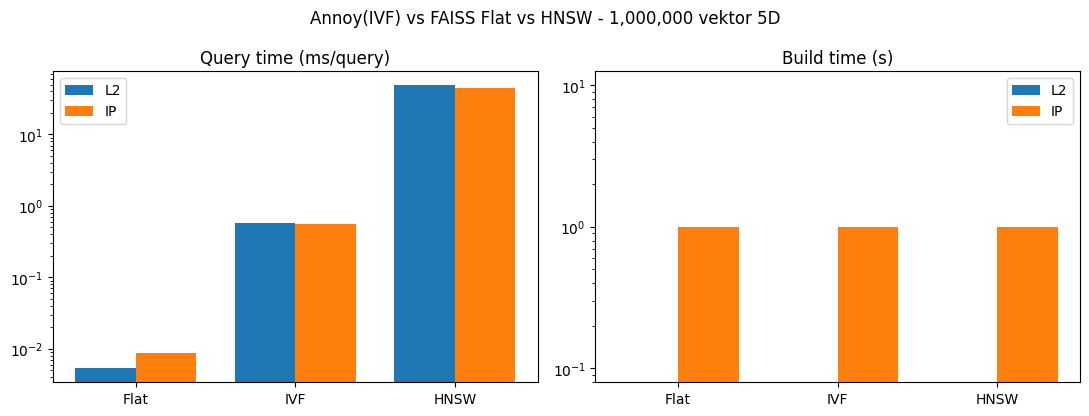

In [4]:
def recall(pred, gt):
    return float(np.mean([len(set(p) & set(g)) / K for p, g in zip(pred, gt)]))


rows, plot_rows = [], []
for metric in ["l2", "ip"]:
    rng = np.random.default_rng(42)
    if metric == "ip":
        X = unit(rng.standard_normal((N, D), dtype=np.float32))
        Q = unit(rng.standard_normal((NQ, D), dtype=np.float32))
        mf = faiss.METRIC_INNER_PRODUCT
    else:
        X = rng.random((N, D), dtype=np.float32)
        Q = rng.random((NQ, D), dtype=np.float32)
        mf = faiss.METRIC_L2

    flat = faiss.IndexFlat(D, mf)
    t0 = time.perf_counter()
    flat.add(X)
    b_flat = time.perf_counter() - t0
    t0 = time.perf_counter()
    _, I_gt = flat.search(Q, K)
    q_flat = (time.perf_counter() - t0) / NQ * 1000

    ivf = faiss.IndexIVFFlat(faiss.IndexFlat(D, mf), D, 100, mf)
    t0 = time.perf_counter()
    ivf.train(X)
    ivf.add(X)
    b_ivf = time.perf_counter() - t0
    ivf.nprobe = 10
    t0 = time.perf_counter()
    _, I_ivf = ivf.search(Q, K)
    q_ivf = (time.perf_counter() - t0) / NQ * 1000

    hnsw = faiss.IndexHNSWFlat(D, 16, mf)
    hnsw.hnsw.efConstruction = 200
    t0 = time.perf_counter()
    hnsw.add(X)
    b_hnsw = time.perf_counter() - t0
    hnsw.hnsw.efSearch = 50
    t0 = time.perf_counter()
    _, I_hnsw = hnsw.search(Q, K)
    q_hnsw = (time.perf_counter() - t0) / NQ * 1000

    res = {
        "faiss_flat": (b_flat, q_flat, I_gt, 1.0),
        "annoy_proxy_ivf": (b_ivf, q_ivf, I_ivf, recall(I_ivf, I_gt)),
        "hnsw_faiss": (b_hnsw, q_hnsw, I_hnsw, recall(I_hnsw, I_gt)),
    }
    print(f"\n=== {metric.upper()} | N={N:,} d={D} k={K} ===")
    for name, (b, q, I, rec) in res.items():
        rows.append([metric, name, round(b, 3), round(q, 3), round(rec, 3), list(map(int, I[0][:5]))])
        plot_rows.append((metric, name, b, q, rec))
        print(f"{name:16s} build {b:7.3f} s | query {q:7.3f} ms | recall@{K}={rec:.3f} | top5 {I[0][:5]}")

with open(OUT / "hasil_tabel.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["metrik", "metode", "build_s", "query_ms", "recall@10", "top5"])
    w.writerows(rows)

names = ["faiss_flat", "annoy_proxy_ivf", "hnsw_faiss"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, idx, title, logy in [(axes[0], 2, "Query time (ms/query)", True),
                             (axes[1], 0, "Build time (s)", True)]:
    for j, metric in enumerate(["l2", "ip"]):
        vals = [r[idx] for r in plot_rows if r[0] == metric]
        ax.bar(np.arange(3) + j * 0.38, vals, width=0.38, label=metric.upper())
    ax.set_xticks(np.arange(3) + 0.19)
    ax.set_xticklabels(["Flat", "IVF", "HNSW"])
    ax.set_yscale("log" if logy else "linear")
    ax.set_title(title)
    ax.legend()
fig.suptitle(f"Annoy(IVF) vs FAISS Flat vs HNSW - {N:,} vektor {D}D")
fig.tight_layout()
fig.savefig(OUT / "p4_perbandingan.png", dpi=120)
for metric in ["l2", "ip"]:
    print(f"recall {metric.upper()}: " + ", ".join(
        f"{r[1]}={r[4]:.3f}" for r in plot_rows if r[0] == metric))